In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import os 
print(os.getcwd())
print(os.listdir())

C:\Users\G\Downloads\netflix_project
['.ipynb_checkpoints', 'netflix_analysis.ipynb', 'netflix_project']


In [4]:
df = pd.read_csv('netflix_project/Dataset.csv')

In [5]:
print(os.listdir('netflix_project'))

['analysis.py', 'charts', 'Dataset.csv', 'outputs', 'REPORT_AND_GUIDE.md']


In [7]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [8]:
df.shape

(8790, 10)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB


In [10]:
df.isna().sum()

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [11]:
df['director'].value_counts().head()
df['country'].value_counts().head()

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Name: count, dtype: int64

In [12]:
(df['director'] == 'WORD').sum()
(df['country'] == 'WORD').sum()

np.int64(0)

In [13]:
df['director'].value_counts().head()

director
Not Given                 2588
Rajiv Chilaka               20
Raúl Campos, Jan Suter      18
Alastair Fothergill         18
Suhas Kadav                 16
Name: count, dtype: int64

In [14]:
(df['director'] == 'Not Given').sum()

np.int64(2588)

In [15]:
(df['country'] == 'Not Given').sum()

np.int64(287)

In [16]:
  df['country'] = df['country'].replace('Not Given', 'Unknown')

In [17]:
df['director'] = df['director'].replace('Not Given', 'Unknown')

In [18]:
(df['director'] == 'Unknown').sum()

np.int64(2588)

In [19]:
(df['country'] == 'Unknown').sum()

np.int64(287)

In [20]:
df.duplicated().sum()
df.duplicated(subset=['title', 'type', 'release_year']).sum()

np.int64(3)

In [21]:
df[df.duplicated(subset=['title', 'type', 'release_year'], keep=False)]

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
393,s3997,TV Show,9-Feb,Unknown,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Unknown,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"


In [22]:
df[df.duplicated(subset=['title', 'type', 'release_year'], keep=False)]

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
393,s3997,TV Show,9-Feb,Unknown,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Unknown,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"


In [23]:
df['date_added'] = pd.to_datetime(df['date_added'])

In [24]:
   for col in ['type', 'title', 'director', 'country', 'rating', 'listed_in', 'duration']:
       df[col] = df[col].str.strip()

In [25]:
   df.duplicated(subset=['title', 'type', 'release_year']).sum()

np.int64(4)

In [26]:
   df = df.drop_duplicates(subset=['title', 'type', 'release_year'])
   df.shape

(8786, 10)

In [27]:
   df.info()

<class 'pandas.DataFrame'>
Index: 8786 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8786 non-null   str           
 1   type          8786 non-null   str           
 2   title         8786 non-null   str           
 3   director      8786 non-null   str           
 4   country       8786 non-null   str           
 5   date_added    8786 non-null   datetime64[us]
 6   release_year  8786 non-null   int64         
 7   rating        8786 non-null   str           
 8   duration      8786 non-null   str           
 9   listed_in     8786 non-null   str           
dtypes: datetime64[us](1), int64(1), str(8)
memory usage: 755.0 KB


In [28]:
   df['type'].value_counts()

type
Movie      6123
TV Show    2663
Name: count, dtype: int64

In [29]:
   df['rating'].value_counts()

rating
TV-MA       3204
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

In [30]:
   df['country'].value_counts().head(20)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Egypt              123
Australia          114
Turkey             111
Nigeria            105
Germany            104
China              100
Brazil              88
Taiwan              86
Indonesia           86
Name: count, dtype: int64

In [31]:
   df['country'].str.contains(',').sum()

np.int64(0)

In [32]:
   df['country'].nunique()

86

In [33]:
df['rating'] = df['rating'].replace('OLD', 'NEW')

In [34]:
df['rating'] = df['rating'].replace('UR', 'NR')

In [35]:
df['rating'].value_counts()

rating
TV-MA       3204
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            82
G             41
TV-Y7-FV       6
NC-17          3
Name: count, dtype: int64

In [36]:
df.to_csv('netflix_cleaned.csv', index=False)

In [37]:
os.listdir()

['.ipynb_checkpoints',
 'netflix_analysis.ipynb',
 'netflix_cleaned.csv',
 'netflix_project']

In [39]:
#Task 2-content Type analysis
df2 = pd.read_csv('netflix_cleaned.csv', parse_dates=['date_added'])
df2.shape

(8786, 10)

In [40]:
counts = df2['type'].value_counts()
counts

type
Movie      6123
TV Show    2663
Name: count, dtype: int64

In [41]:
percent = df2['type'].value_counts(normalize=True) * 100
percent.round(1)

type
Movie      69.7
TV Show    30.3
Name: proportion, dtype: float64

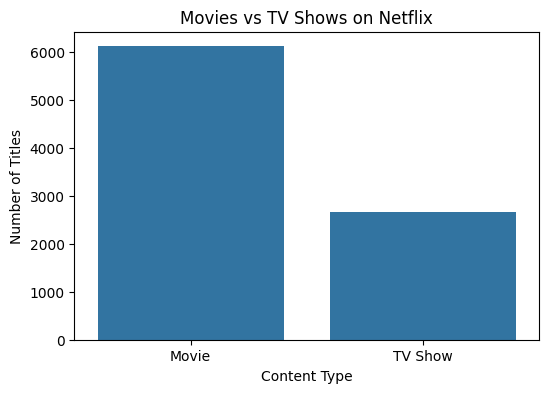

In [42]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df2, x='type')
plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()

([<matplotlib.patches.Wedge at 0x2956acb52b0>,
 [Text(-0.6378783168833221, 0.8961647464892268, 'Movie'),
  Text(0.6378781815662028, -0.8961648428061628, 'TV Show')],
 [Text(-0.3479336273909029, 0.48881713444866914, '69.7%'),
  Text(0.34793355358156514, -0.4888171869851797, '30.3%')])

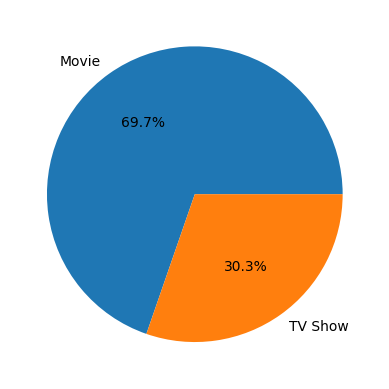

In [43]:
plt.pie(counts, labels=counts.index, autopct='%1.1f%%')

In [44]:
df2['year_added'] = df2['date_added'].dt.year
by_year = df2.groupby(['year_added', 'type']).size().unstack(fill_value=0)
by_year

type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,251,175


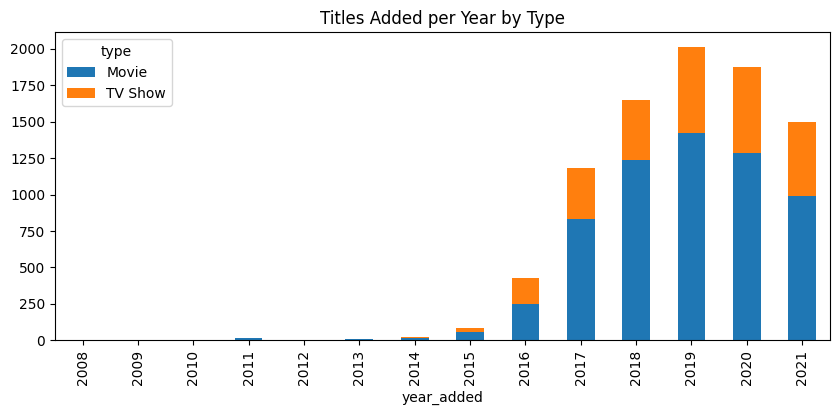

In [45]:
by_year.plot(kind='bar', stacked=True, figsize=(10, 4))
plt.title('Titles Added per Year by Type')
plt.show()

In [46]:
   by_year['tv_share_%'] = (by_year['TV Show'] / by_year.sum(axis=1) * 100).round(1)
   by_year

type,Movie,TV Show,tv_share_%
year_added,,,
2008,1,1,50.0
2009,2,0,0.0
2010,1,0,0.0
2011,13,0,0.0
2012,3,0,0.0
2013,6,5,45.5
2014,19,5,20.8
2015,56,26,31.7
2016,251,175,41.1


In [47]:
The Netflix catalogue has 8,786 titles after cleaning. There are 6,123 Movies (69.7%) and 2,663 TV Shows (30.3%), so there are about 2.3 times more Movies than TV Shows. The most titles were added in 2019, with 1,422 Movies and 591 TV Shows. The second-highest year was 2020, with 1,284 Movies and 595 TV Shows. Overall, Movies make up most of the catalogue.

In [49]:
## Task 1 Summary - Data Cleaning

##Dataset size:The original dataset had 8,790 rows and 10 columns. After cleaning it has 8,786 rows and 10 columns.

##Missing values: The dataset had no empty cells, but it used the placeholder text "Not Given" for missing information. This appeared 2,588 times in `director` and 287 times in `country`. I replaced it with "Unknown" so that these rows are kept and clearly labelled.

##Duplicates: I removed 4 duplicate records. They had the same title, type and release year but different `show_id` values, so they were the same title listed twice. I kept the first copy of each. Trimming extra spaces before checking revealed one more duplicate that was hidden at first.

##Formatting: I removed extra spaces from the text columns and converted `date_added` from text to a proper date format, so it can be used for year-based analysis.

##Standardisation: I checked `type`, `rating` and `country`. `type` and `country` were already consistent. In `rating`, "UR" and "NR" both mean "not rated", so I merged "UR" into "NR" (82 titles in total).

##Export: The cleaned data was saved as `netflix_cleaned.csv` and used for all later tasks.

In [50]:
# Task 3 - Country Analysis
df2['country'].nunique()

86

In [52]:
country_counts = df2['country'].value_counts()
country_counts.head(10)

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

In [53]:
top10 = df2[df2['country'] != 'Unknown']['country'].value_counts().head(10)
top10

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

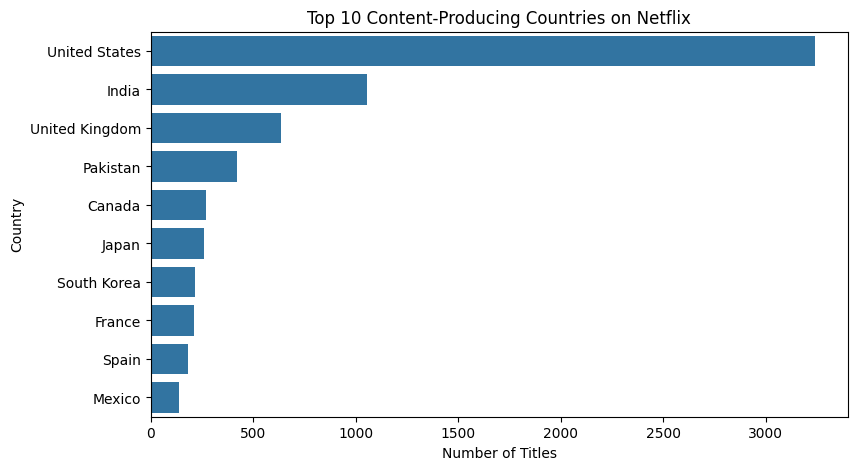

In [54]:
plt.figure(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index)
plt.title('Top 10 Content-Producing Countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

In [55]:
top_df = df2[df2['country'].isin(top10.index)]

In [56]:
mix = top_df.groupby(['country', 'type']).size().unstack(fill_value=0)
mix

type,Movie,TV Show
country,,
Canada,187,84
France,148,65
India,975,81
Japan,87,172
Mexico,90,48
Pakistan,71,349
South Korea,49,165
Spain,129,53
United Kingdom,387,251


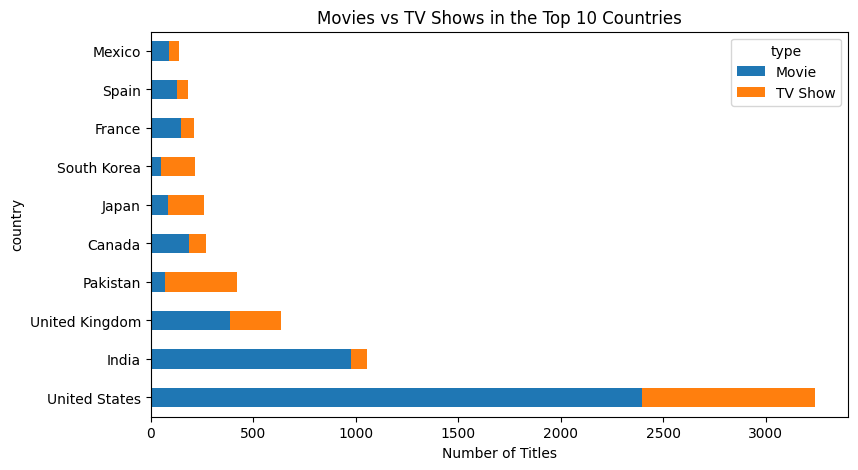

In [57]:
mix.loc[top10.index].plot(kind='barh', stacked=True, figsize=(9, 5))
plt.title('Movies vs TV Shows in the Top 10 Countries')
plt.xlabel('Number of Titles')
plt.show()

In [58]:
share = (top10 / len(df2) * 100).round(1)
share

country
United States     36.9
India             12.0
United Kingdom     7.3
Pakistan           4.8
Canada             3.1
Japan              2.9
South Korea        2.4
France             2.4
Spain              2.1
Mexico             1.6
Name: count, dtype: float64

In [59]:
## Summary

#The United States ranks first with 36.9% of all titles (3,240), followed by India with 12.0% (1,056). The United States has 2,395 Movies and 845 TV Shows. India is mostly Movies (975 Movies and 81 TV Shows), while South Korea is the opposite, with more TV Shows than Movies (165 TV Shows and 49 Movies). This suggests that Netflix could focus on films in India and on series in South Korea. 287 titles have an Unknown country and are not included in the ranking.

In [3]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\G\Downloads\netflix_project
['.ipynb_checkpoints', 'netflix_analysis.ipynb', 'netflix_cleaned.csv', 'netflix_project']


In [4]:
  df = pd.read_csv("netflix_cleaned.csv")

In [7]:
   df = pd.read_csv("netflix_cleaned.csv", parse_dates=["date_added"])
   print(df.shape)
   df.head()

(8786, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [8]:
   yearly = df.groupby("release_year").size()
   recent = yearly[yearly.index >= 2000]
   recent

release_year
2000      37
2001      45
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     351
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
dtype: int64

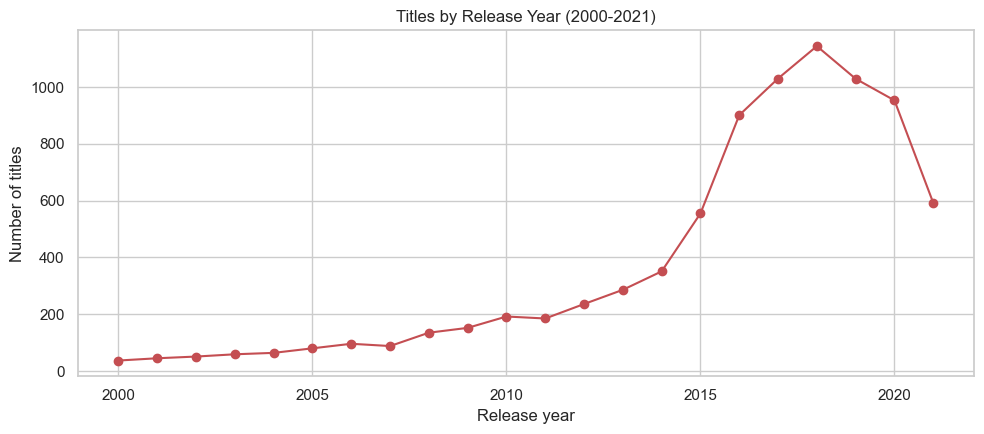

In [9]:

recent.plot(kind="line", marker="o", figsize=(10, 4.5), color="#C44E52")
plt.title("Titles by Release Year (2000-2021)")
plt.xlabel("Release year"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()

In [10]:

print("Peak year:", yearly.idxmax(), "with", yearly.max(), "titles")
print(yearly.pct_change().mul(100).round(1).tail(5))

Peak year: 2018 with 1144 titles
release_year
2017    14.3
2018    11.1
2019   -10.1
2020    -7.4
2021   -37.9
dtype: float64


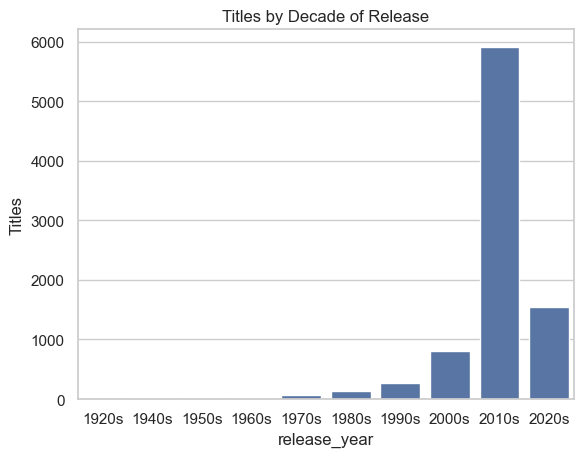

In [11]:

decade = (df["release_year"] // 10 * 10).value_counts().sort_index()
sns.barplot(x=decade.index.astype(str) + "s", y=decade.values, color="#4C72B0")
plt.title("Titles by Decade of Release"); plt.ylabel("Titles"); plt.show()

In [13]:
## Summary: Release-Year Trend

# Netflix's catalogue is dominated by recent releases. Titles released in 2018 peak at 1,144, the highest of any year.
#Releases then decline: 1,029 in 2019 and 953 in 2020. The 2021 figure (592) is low mainly because the dataset ends in September 2021, so that year is incomplete.
# By decade, the 2010s account for 5,909 titles, about 67% of the catalogue. Older content (before 2000) is a small share.
#Movies outnumber TV shows in almost every release year, but TV shows grew faster in the late 2010s.
# Titles added to Netflix peaked in 2019 (2,013) after rising from only 82 in 2015, which points to rapid expansion followed by a slowdown.

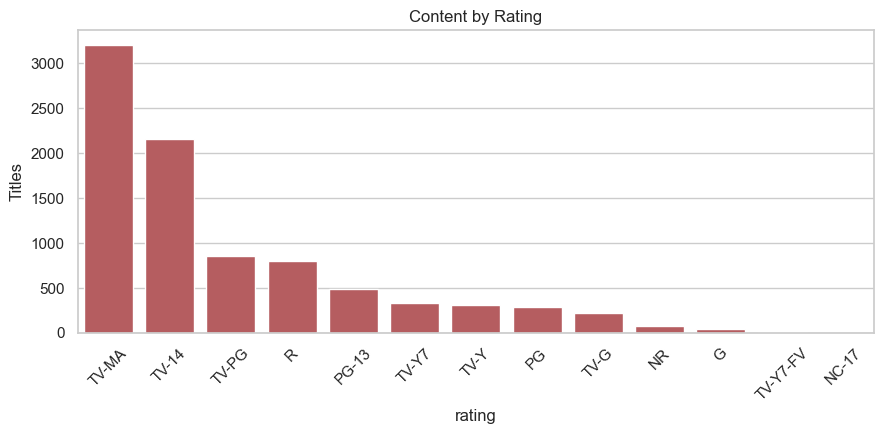

rating
TV-MA    3204
TV-14    2155
TV-PG     861
R         798
PG-13     490
Name: count, dtype: int64

In [14]:
rc = df["rating"].value_counts()
plt.figure(figsize=(9, 4.5))
sns.barplot(x=rc.index, y=rc.values, color="#C44E52")
plt.xticks(rotation=45)
plt.title("Content by Rating"); plt.ylabel("Titles")
plt.tight_layout(); plt.show()
rc.head()

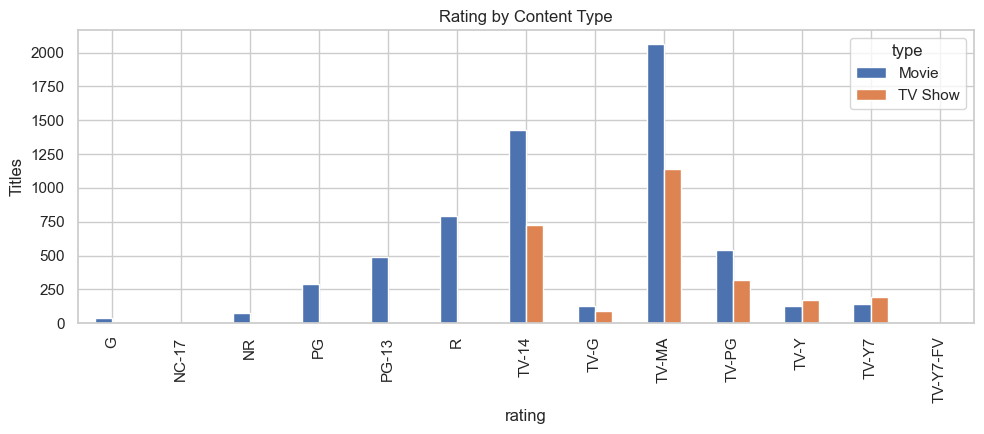

In [15]:
rt = pd.crosstab(df["rating"], df["type"])
rt.plot(kind="bar", figsize=(10, 4.5))
plt.title("Rating by Content Type"); plt.ylabel("Titles")
plt.tight_layout(); plt.show()

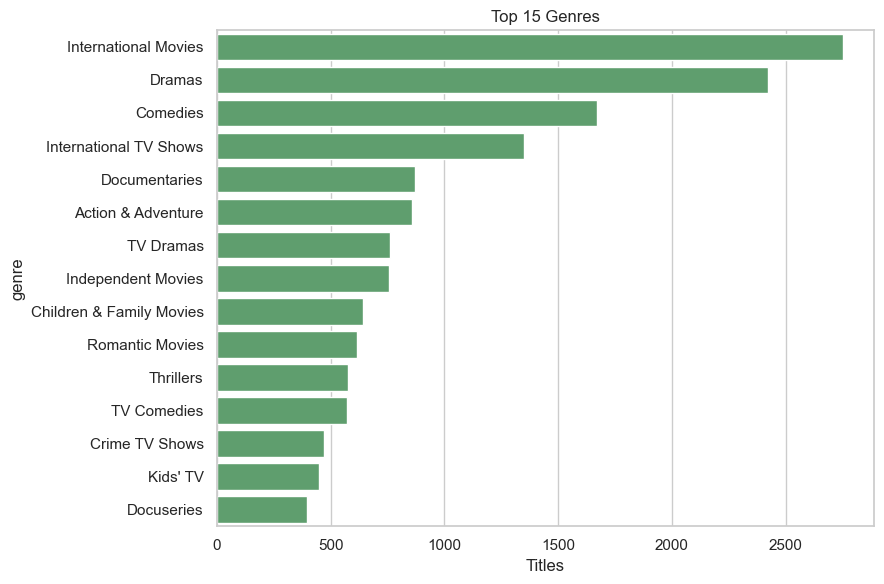

genre
International Movies        2751
Dramas                      2423
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

In [16]:
g = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre").reset_index(drop=True)
gen = g["genre"].value_counts()
plt.figure(figsize=(9, 6))
sns.barplot(x=gen.head(15).values, y=gen.head(15).index, color="#55A868")
plt.title("Top 15 Genres"); plt.xlabel("Titles")
plt.tight_layout(); plt.show()
gen.head(10)

In [18]:
rating_group = {"TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
                "TV-PG": "Older Kids", "PG": "Older Kids",
                "TV-14": "Teens", "PG-13": "Teens",
                "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
                "NR": "Not Rated", "UR": "Not Rated"}
df["audience"] = df["rating"].map(rating_group)
df["audience"].value_counts(dropna=False)

audience
Adults        4005
Teens         2645
Older Kids    1148
Kids           906
Not Rated       82
Name: count, dtype: int64

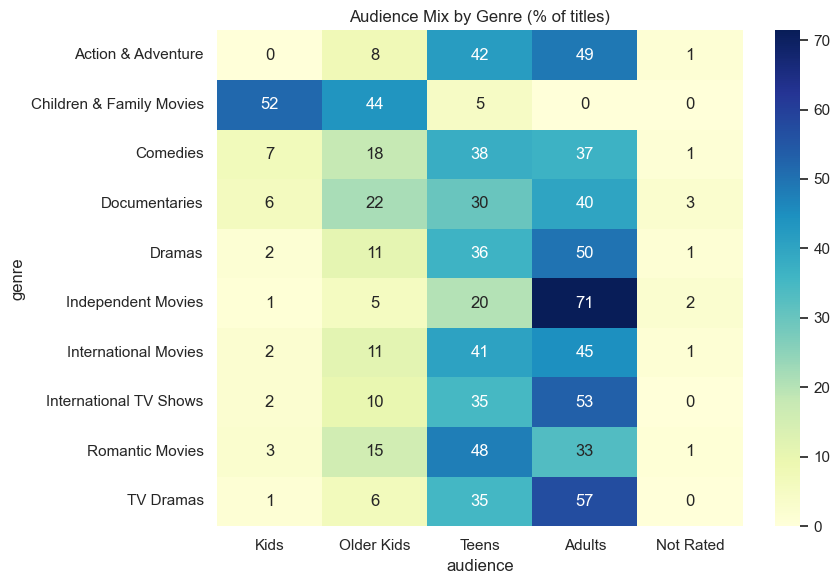

In [19]:
g = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre").reset_index(drop=True)
gen = g["genre"].value_counts()
top = gen.head(10).index
sub = g[g["genre"].isin(top)]
h = pd.crosstab(sub["genre"], sub["audience"], normalize="index") * 100
h = h[["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]]
plt.figure(figsize=(9, 6))
sns.heatmap(h, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Audience Mix by Genre (% of titles)")
plt.tight_layout(); plt.show()

In [20]:
h = h.reindex(columns=["Kids", "Older Kids", "Teens", "Adults", "Not Rated"], fill_value=0)

In [ ]:
pip install plotly

In [1]:
import plotly.express as px

gt = sub.groupby(["genre", "type"]).size().reset_index(name="count")
fig1 = px.bar(gt, x="count", y="genre", color="type", orientation="h",
              title="Top 10 Genres by Content Type")
fig1.update_layout(yaxis={"categoryorder": "total ascending"})
fig1.show()

NameError: name 'sub' is not defined

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid")
df = pd.read_csv("netflix_cleaned.csv", parse_dates=["date_added"])

rating_group = {"TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
                "TV-PG": "Older Kids", "PG": "Older Kids",
                "TV-14": "Teens", "PG-13": "Teens",
                "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
                "NR": "Not Rated", "UR": "Not Rated"}
df["audience"] = df["rating"].map(rating_group)

g = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre").reset_index(drop=True)
gen = g["genre"].value_counts()
top = gen.head(10).index
sub = g[g["genre"].isin(top)]
h = pd.crosstab(sub["genre"], sub["audience"], normalize="index") * 100
h = h.reindex(columns=["Kids", "Older Kids", "Teens", "Adults", "Not Rated"], fill_value=0)

print(df.shape, df["audience"].isna().sum())

(8786, 11) 0


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("netflix_cleaned.csv", parse_dates=["date_added"])

rating_group = {"TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
                "TV-PG": "Older Kids", "PG": "Older Kids",
                "TV-14": "Teens", "PG-13": "Teens",
                "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
                "NR": "Not Rated", "UR": "Not Rated"}
df["audience"] = df["rating"].map(rating_group)

g = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre").reset_index(drop=True)
gen = g["genre"].value_counts()
top = gen.head(10).index
sub = g[g["genre"].isin(top)]
h = pd.crosstab(sub["genre"], sub["audience"], normalize="index") * 100
h = h.reindex(columns=["Kids", "Older Kids", "Teens", "Adults", "Not Rated"], fill_value=0)

gt = sub.groupby(["genre", "type"]).size().reset_index(name="count")
fig1 = px.bar(gt, x="count", y="genre", color="type", orientation="h",
              title="Top 10 Genres by Content Type")
fig1.update_layout(yaxis={"categoryorder": "total ascending"})
fig1.show()

In [3]:
rt2 = df.groupby(["rating", "type"]).size().reset_index(name="count")
fig2 = px.bar(rt2, x="rating", y="count", color="type", barmode="group",
              title="Ratings by Content Type")
fig2.show()

In [4]:
hp = h.reset_index().melt(id_vars="genre", var_name="audience", value_name="percent")
fig3 = px.bar(hp, x="audience", y="percent", color="audience", animation_frame="genre",
              range_y=[0, 100], title="Audience Mix by Genre (use the slider)")
fig3.show()

In [5]:
import os
os.makedirs("outputs", exist_ok=True)
fig1.write_html("outputs/task5_genres_interactive.html")
fig2.write_html("outputs/task5_ratings_interactive.html")
fig3.write_html("outputs/task5_audience_interactive.html")

In [6]:
## Summary

#From the rating chart, most of the content on Netflix is for mature viewers. TV-MA is the biggest rating with 3,204 titles, and TV-14 comes next with 2,155. When I grouped the ratings by audience, adults came to about 46% of all titles and teens about 30%. Kids content is much smaller, roughly 23% if I add Kids and Older Kids together.
#I was surprised that Dramas are 50% adult
#For genres, International Movies is the biggest (2,751 titles), then Dramas (2,423) and Comedies (1,673). This shows that Netflix has a lot of international content and that drama and comedy are what it mostly offers.

#The heatmap was the most useful chart. The audience is different for each genre. Independent Movies are 71% adult content and Dramas are 50% adult, while Children & Family Movies are almost all Kids or Older Kids. Action & Adventure is mostly for teens and adults.

#In the interactive charts I could hover to see exact counts and click on Movie or TV Show in the legend to compare them. The genre slider made it easy to look at the audience mix for each genre one by one.

#Overall, Netflix leans towards adult and teen content, and kids content is the smallest group.
### Creating the "audience" column
#The dataset has a rating column (TV-MA, PG-13, etc.) but no simple age group. To make the analysis easier, I grouped the ratings into five audience groups:

#**Kids:** TV-Y, TV-Y7, TV-Y7-FV, TV-G, G
#**Older Kids:** TV-PG, PG
#**Teens:** TV-14, PG-13
#**Adults:** TV-MA, R, NC-17
#**Not Rated:** NR, UR

#This grouping is my own choice, based on the usual meaning of each rating. Other people might group them differently.

In [10]:
import numpy as np

# split duration into minutes (movies) and seasons (TV shows)
num = df["duration"].str.extract(r"(\d+)")[0].astype(int)
df["duration_min"] = np.where(df["type"] == "Movie", num, np.nan)
df["seasons"] = np.where(df["type"] == "TV Show", num, np.nan)

# year the title was added to Netflix
df["date_added"] = pd.to_datetime(df["date_added"], format="mixed")
df["year_added"] = df["date_added"].dt.year

mv = df.loc[df["type"] == "Movie", "duration_min"].dropna()
sn = df.loc[df["type"] == "TV Show", "seasons"].dropna().astype(int)
print("Median movie runtime:", mv.median())                              # 98.0
print("TV shows with 1 season (%):", round((sn == 1).mean() * 100, 1))   # 67.2

Median movie runtime: 98.0
TV shows with 1 season (%): 67.2


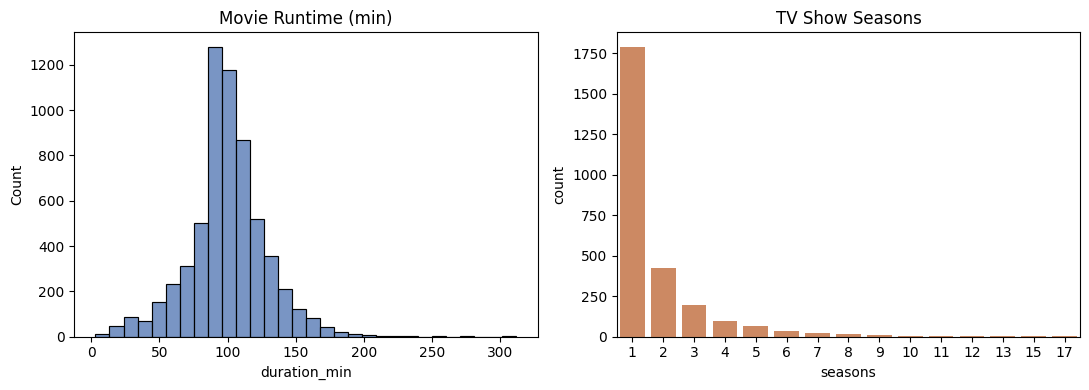

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(mv, bins=30, ax=ax[0], color="#4C72B0"); ax[0].set_title("Movie Runtime (min)")
sns.countplot(x=sn, ax=ax[1], color="#DD8452"); ax[1].set_title("TV Show Seasons")
plt.tight_layout(); plt.show()

In [12]:
known = df[df["country"] != "Unknown"]
tv_share = known.groupby("country")["type"].apply(lambda s: (s == "TV Show").mean() * 100).round(1)
top_c = known["country"].value_counts().head(7)
print(top_c)
print(tv_share[top_c.index])

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
Name: count, dtype: int64
country
United States     26.1
India              7.7
United Kingdom    39.3
Pakistan          83.1
Canada            31.0
Japan             66.4
South Korea       77.1
Name: type, dtype: float64


In [13]:
g = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre").reset_index(drop=True)

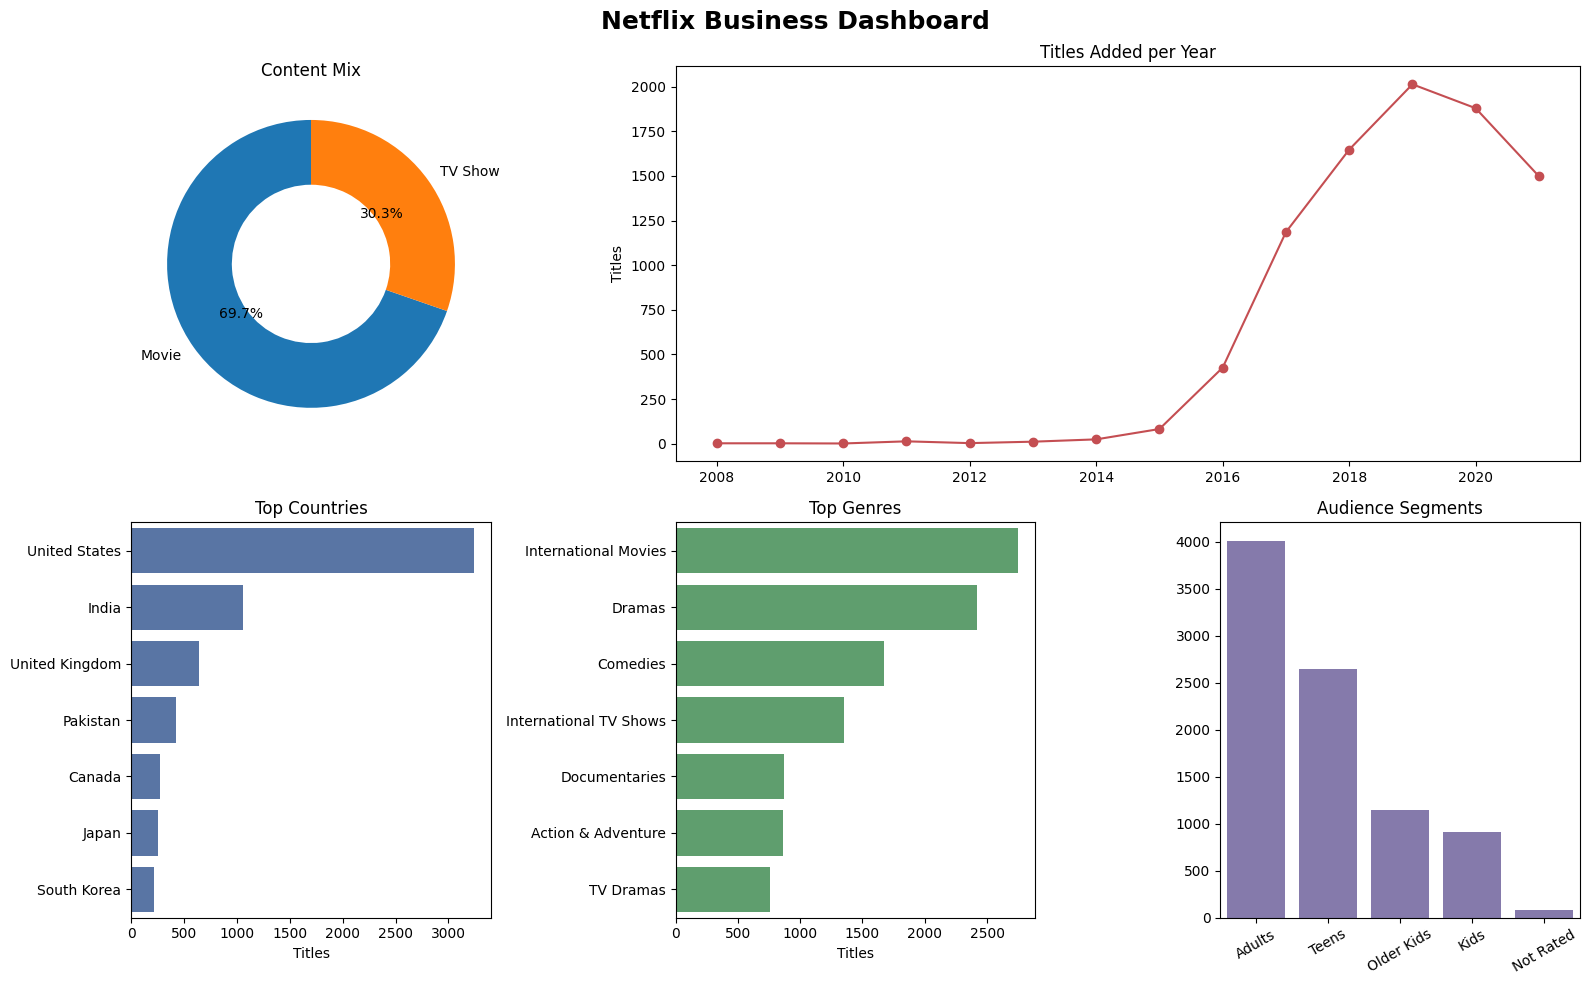

In [14]:
tc = df["type"].value_counts()
ya = df.groupby("year_added").size()
aud = df["audience"].value_counts()
gen = g["genre"].value_counts()

fig = plt.figure(figsize=(16, 10)); gs = fig.add_gridspec(2, 3)
a = fig.add_subplot(gs[0, 0]); a.pie(tc.values, labels=tc.index, autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=.45)); a.set_title("Content Mix")
a = fig.add_subplot(gs[0, 1:]); a.plot(ya.index, ya.values, marker="o", color="#C44E52"); a.set_title("Titles Added per Year"); a.set_ylabel("Titles")
a = fig.add_subplot(gs[1, 0]); sns.barplot(x=top_c.values, y=top_c.index, ax=a, color="#4C72B0"); a.set_title("Top Countries"); a.set_ylabel(""); a.set_xlabel("Titles")
a = fig.add_subplot(gs[1, 1]); sns.barplot(x=gen.head(7).values, y=gen.head(7).index, ax=a, color="#55A868"); a.set_title("Top Genres"); a.set_ylabel(""); a.set_xlabel("Titles")
a = fig.add_subplot(gs[1, 2]); sns.barplot(x=aud.index, y=aud.values, ax=a, color="#8172B3"); a.set_title("Audience Segments"); a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
fig.suptitle("Netflix Business Dashboard", fontsize=18, weight="bold")
plt.tight_layout(); plt.savefig("task6_dashboard.png", dpi=150); plt.show()

In [1]:
## Task 6: Business Insights

#In this task I put the main results from the whole analysis into one dashboard and wrote down what I think Netflix can learn from it.

#**What the dashboard shows**
#- About 70% of the titles are movies and 30% are TV shows.
#- The US has the most titles by far (3,240). India is second (1,056) and the UK is third (638).
#- The number of titles added per year went up fast from 2016 and was highest in 2019 (2,013). It went down a bit in 2020. 2021 looks lower, but the data only goes up to September 2021, so that year is not complete.
#- International Movies, Dramas and Comedies are the biggest genres.
#- Adults is the biggest audience group (4,005 titles) and Teens is second (2,645). Kids and Older Kids are much smaller.

#**Other things I found**
#- The median movie is 98 minutes long.
#- About 67% of the TV shows have only one season.
#- In South Korea, Pakistan and Japan most of the titles are TV shows. In India it is the other way, only about 8% are TV shows.

#**What I think Netflix could do**
#1. Add more kids and family content, because it is a small part of the catalogue right now.
#2. Make more local content for countries like India, the UK and Pakistan, since they already have a lot of titles.
#3. Pick the format by country. For example, series work more in Asian countries like South Korea, and movies work more in India.
#4. Look at why so many shows stop after one season. Maybe they are limited series, or maybe they get cancelled.

#**Limits of this analysis**
#- The data stops in September 2021.
#- 287 titles have no country, so I left them out of the country results.
#- The data only shows what is on Netflix, not how many people watched it, so I can't say which content is actually popular.